# Conditional WGAN-GP for face generation

A convolutional generator creates 64 × 64 RGB faces from random noise and one of six age groups. The notebook covers data preparation, training and evaluation. The displayed results come from a completed run with seed 123.

Set the dataset path in the setup cell before running the notebook. See [README.md](README.md) for the required HDF5 layout and instructions. A GPU is recommended for training.

In [ ]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import json
from pathlib import Path
import hashlib

import h5py
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

import keras
import tensorflow as tf

from datetime import datetime

keras.backend.clear_session()
print(tf.config.list_physical_devices("GPU"))
import platform
from scipy.ndimage import gaussian_filter

### 1. Dataset inspection and preparation

The FACE dataset contains RGB images with age, gender and ethnic-group labels. Age is the condition used in this experiment.


In [ ]:
from os import environ

DATA_PATH = Path(environ.get("FACE_DATA_PATH", "data/UTKFace_64x64.h5"))
RESULT_DIR = Path(environ.get("FACE_RESULTS_DIR", "results"))

if not DATA_PATH.is_file():
  raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. See README.md.")

RESULT_DIR.mkdir(parents=True, exist_ok=True)
assert RESULT_DIR.is_dir(), f"Directory {RESULT_DIR} does not exist."
RUN_DIR = RESULT_DIR / (
  "wgan_final_concat_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Run directory:", RUN_DIR)

with h5py.File(DATA_PATH, "r") as f:
  file_summary = pd.DataFrame([
    {
      "Key": key,
      "Shape": f[key].shape,
      "Dtype": str(f[key].dtype)
    } for key in f.keys()
  ])
  images = f["images"][:]
  ages = f["labels"][:]
  genders = f["genders"][:]
  races = f["races"][:]
  provided_train_idx = f["indx_train"][:]
  provided_valid_idx = f["indx_valid"][:]

display(file_summary)

In [ ]:
assert images.ndim == 4 and images.shape[1:] == (3, 64, 64)
assert images.dtype == np.uint8
images = np.transpose(images, (0, 2, 3, 1))
n_images = len(images)

assert ages.shape == genders.shape == races.shape == (n_images,)
assert np.isfinite(ages).all() and (ages >= 0).all()
assert np.isin(genders, [0, 1]).all()
assert np.isin(races, [0, 1, 2, 3, 4]).all()

for indices in (provided_train_idx, provided_valid_idx):
    assert indices.ndim == 1 and np.issubdtype(indices.dtype, np.integer)
    assert ((indices >= 0) & (indices < n_images)).all()
    assert len(np.unique(indices)) == len(indices)

assert np.intersect1d(provided_train_idx, provided_valid_idx).size == 0
assert len(provided_train_idx) + len(provided_valid_idx) == n_images

print("Images:", images.shape, images.dtype, images.min(), images.max())
print("Ages:", ages.min(), "-", ages.max(), "| mean:", round(float(ages.mean()), 1))
print("Genders:", pd.Series(genders).value_counts().to_dict())
print("Races:", pd.Series(races).value_counts().to_dict())

In [ ]:
SEED = 123
rng = np.random.default_rng(SEED)

GENDER_NAMES = {0: "Male", 1: "Female"}
RACE_NAMES = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Other"}

#### Duplicate images and data splits

Exact duplicates are grouped before splitting so that copies stay in the same split. In each split, one copy is kept when all copies have the same age group. Groups with missing or conflicting age groups are excluded.

In [ ]:
images_hashes = np.array([
  hashlib.sha256(image.tobytes()).hexdigest() for image in images
])
_, first_idx, image_group = np.unique(
  images_hashes, return_index=True, return_inverse=True
)
group_ids = np.arange(len(first_idx))
group_ages = ages[first_idx]

development_groups, test_groups = train_test_split(
  group_ids, test_size=0.1, random_state=SEED, stratify=group_ages
)

train_groups, valid_groups = train_test_split(
  development_groups, test_size=0.1, random_state=SEED, stratify=group_ages[development_groups]
)

train_idx = np.flatnonzero(np.isin(image_group, train_groups))
valid_idx = np.flatnonzero(np.isin(image_group, valid_groups))
test_idx = np.flatnonzero(np.isin(image_group, test_groups))

for left, right in [(train_idx, valid_idx), (train_idx, test_idx), (valid_idx, test_idx)]:
  assert np.intersect1d(left, right).size == 0
  assert np.intersect1d(image_group[left], image_group[right]).size == 0
all_indices = np.concatenate([train_idx, valid_idx, test_idx])
assert np.array_equal(np.sort(all_indices), np.arange(n_images))

print("Exact duplicate beyond the first copy:", n_images - len(group_ids))
for name, indices in [("train", train_idx), ("valid", valid_idx), ("test", test_idx)]:
  print(f"{name}: {len(indices):,} images ({100 * len(indices) / n_images:.2f}%)")

In [ ]:
image_group = image_group.ravel()
group_sizes = np.bincount(image_group)
dup_groups = np.flatnonzero(group_sizes > 1)
print(f"Number of groups with duplicates: {len(dup_groups)}")

if len(dup_groups) == 0:
  print("No duplicate groups found.")
else:
  sizes, counts = np.unique(group_sizes[dup_groups], return_counts=True)
  print(f"Size of the group -> number of groups: {dict(zip(sizes.tolist(), counts.tolist()))}")

  # Duplicate groups are expected to have the same age, gender, and race.
  conflicts = []
  for g in dup_groups:
    members = np.flatnonzero(image_group == g)
    assert all(np.array_equal(images[members[0]], images[m]) for m in members[1:])
    if len(np.unique(ages[members])) > 1 or len(np.unique(genders[members])) > 1 or len(np.unique(races[members])) > 1:
      conflicts.append((g, members.tolist(), ages[members].tolist(), genders[members].tolist(), races[members].tolist()))
  print(f"Groups with conflicting attributes: {len(conflicts)}")

  if not conflicts:
    print("No conflicting groups found.")
  else:
    N_GROUPS = min(8, len(conflicts))
    show = [g for g, *_ in conflicts[:N_GROUPS]]
    max_copies = group_sizes[show].max()

    fig, axes = plt.subplots(
      max_copies,
      N_GROUPS,
      figsize=(N_GROUPS * 2, max_copies * 2),
      squeeze=False,
    )
    for ax in axes.flat:
      ax.axis("off")

    for group_col, g in enumerate(show):
      members = np.flatnonzero(image_group == g)

      for copy_row, m in enumerate(members):
        ax = axes[copy_row, group_col]
        ax.imshow(images[m])
        ax.set_title(f"Age: {ages[m]}\nGender: {genders[m]}\nRace: {races[m]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
metadata = pd.DataFrame({
  "age": ages,
  "gender": pd.Series(genders).map(GENDER_NAMES),
  "race": pd.Series(races).map(RACE_NAMES),
})

metadata.index.name = "image_index"
metadata["split"] = "train"
metadata.loc[valid_idx, "split"] = "validation"
metadata.loc[test_idx, "split"] = "test"

age_bins = [0, 10, 20, 30, 40, 50, 61]
age_groups = ["0–9", "10–19", "20–29", "30–39", "40–49", "50–60"]
metadata["age_group"] = pd.cut(
  metadata["age"], 
  bins=age_bins, 
  labels=age_groups, 
  right=False
)

display(metadata.head())
split_summary = metadata.groupby("split").agg(
  images=("age", "size"),
  mean_age=("age", "mean"),
  median_age=("age", "median"),
  min_age=("age", "min"),
  max_age=("age", "max"),
)
split_summary["percentage"] = 100 * split_summary["images"] / n_images
display(split_summary.round(2))

In [ ]:
data = metadata.copy()
data["image_group"] = image_group.ravel()

groups = data.groupby("image_group")["age_group"]
distinct_bands = groups.transform("nunique")
has_missing_band = data["age_group"].isna().groupby(
  data["image_group"]
).transform("any")

eligible = distinct_bands.eq(1) & ~has_missing_band

gan_metadata = (
  data.loc[eligible]
  .sort_index()
  .drop_duplicates(subset="image_group", keep="first")
  .copy()
)

assert gan_metadata["image_group"].is_unique

print("Excluded groups with conflicting age groups:", data.loc[distinct_bands.gt(1), "image_group"].nunique())
print("Excluded with missing age group:", data.loc[has_missing_band, "image_group"].nunique())

display(pd.concat({
  "Before:": pd.crosstab(data["age_group"], data["split"]),
  "After:": pd.crosstab(gan_metadata["age_group"], gan_metadata["split"])
}, axis=1).fillna(0).astype(int))

In [ ]:
gan_train_idx = gan_metadata.index[
  gan_metadata["split"].eq("train")
].to_numpy()
gan_valid_idx = gan_metadata.index[
  gan_metadata["split"].eq("validation")
].to_numpy()
gan_test_idx = gan_metadata.index[
  gan_metadata["split"].eq("test")
].to_numpy()

assert np.isin(gan_train_idx, train_idx).all()
assert np.isin(gan_valid_idx, valid_idx).all()
assert np.isin(gan_test_idx, test_idx).all()

print(f"Train:      {len(train_idx)} → {len(gan_train_idx)}")
print(f"Validation: {len(valid_idx)} → {len(gan_valid_idx)}")
print(f"Test:       {len(test_idx)} → {len(gan_test_idx)}")

In [ ]:
fig, axes = plt.subplots(5, len(age_groups), figsize=(len(age_groups) * 3, 12), sharey=True)

for col, age_group in enumerate(age_groups):
  candidates = gan_metadata.index[
    (gan_metadata["split"] == "train") & (gan_metadata["age_group"] == age_group)
  ].to_numpy()
  chosen = rng.choice(candidates, size=5, replace=False)

  for row, idx in enumerate(chosen):
    info = gan_metadata.loc[idx]
    axes[row, col].imshow(images[idx])
    axes[row, col].set_title(f"Age: {info['age']}\nGender: {info['gender']}\nRace: {info['race']}")
    axes[row, col].axis("off")

fig.suptitle("Training faces", fontsize=20)
plt.tight_layout()
plt.show()

In [ ]:
split_order = ["train", "validation"]
development_metadata = gan_metadata[gan_metadata["split"].isin(split_order)]

def laber_distribution(column, order):
  counts = pd.crosstab(
    development_metadata[column],
    development_metadata["split"]
  ).reindex(
    index=order,
    columns=split_order,
    fill_value=0
  )
  percentages = counts.div(counts.sum(axis=0), axis=1) * 100
  table = pd.DataFrame({
    "Train counts": counts["train"],
    "Train %": percentages["train"],
    "Validation counts": counts["validation"],
    "Validation %": percentages["validation"]
  })
  return table.round(2), percentages

age_table, _ = laber_distribution("age_group", age_groups)
gender_table, gender_pct = laber_distribution("gender", list(GENDER_NAMES.values()))
race_table, race_pct = laber_distribution("race", list(RACE_NAMES.values()))

for title, table in [
  ("Age group distribution", age_table),
  ("Gender distribution", gender_table),
  ("Race distribution", race_table)
]:
  print(title)
  display(table)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for split in split_order:
  values = development_metadata.loc[development_metadata["split"] == split, "age"].to_numpy()
  axes[0].hist(
    values, bins=np.arange(0.5, 61.5, 1),
    weights=np.full(len(values), 100 / len(values)),
    histtype="step", linewidth=1.8, label=split,
  )
axes[0].set(title="Age distribution", xlabel="Age (years)", ylabel="Images within split (%)")
axes[0].legend()

gender_pct.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Dataset gender labels", xlabel="", ylabel="Images within split (%)")
race_pct.plot.bar(ax=axes[2], rot=25)
axes[2].set(title="Dataset ethnic-group labels", xlabel="", ylabel="Images within split (%)")


plt.tight_layout()
plt.show()

#### Image normalisation and age labels

Pixels are scaled to [0, 1]. Age groups are encoded as one-hot vectors.


In [ ]:
x_train = images[gan_train_idx].astype(np.float32) / 255.0
x_valid = images[gan_valid_idx].astype(np.float32) / 255.0
x_test = images[gan_test_idx].astype(np.float32) / 255.0



assert list(gan_metadata["age_group"].cat.categories) == age_groups

y_train = gan_metadata.loc[gan_train_idx, "age_group"].cat.codes.to_numpy(dtype=np.int32)
y_valid = gan_metadata.loc[gan_valid_idx, "age_group"].cat.codes.to_numpy(dtype=np.int32)
y_test = gan_metadata.loc[gan_test_idx, "age_group"].cat.codes.to_numpy(dtype=np.int32)

for labels in (y_train, y_valid, y_test):
  assert np.isin(labels, np.arange(len(age_groups))).all()

c_train = keras.utils.to_categorical(y_train, num_classes=len(age_groups)).astype(np.float32)
c_valid = keras.utils.to_categorical(y_valid, num_classes=len(age_groups)).astype(np.float32)
c_test = keras.utils.to_categorical(y_test, num_classes=len(age_groups)).astype(np.float32)

assert c_train.shape == (len(y_train), 6)
assert c_valid.shape == (len(y_valid), 6)
assert c_test.shape == (len(y_test), 6)

display(
  pd.DataFrame([
    {
      "Split": name,
      "Shape": array.shape,
      "Min": array.min(),
      "Max": array.max(),
    } for name, array in [("train", x_train), ("validation", x_valid), ("test", x_test)]
  ]).round(2)
)

assert len(x_train) == len(y_train) == len(c_train)
assert len(x_valid) == len(y_valid) == len(c_valid)
assert len(x_test) == len(y_test) == len(c_test)
assert x_train.shape[1:] == x_valid.shape[1:] == x_test.shape[1:] == (64, 64, 3)

### 2. Experimental settings

The experiment uses 128-dimensional noise, batches of 32 and a gradient penalty weight of 10. Training runs for up to 100 epochs.


In [ ]:
CONFIG = {
    "critic_conditioning": "concatenation",
    "generator_architecture": "convtranspose_relu_no_batchnorm",
    "generator_transpose_kernel_size": 4,
    "generator_use_bias": False,
    "early_stopping_patience": 25,
    "sw_num_projections": 128,
    "evaluation_repeats": 5,
    "latent_dim": 128,
    "n_classes": len(age_groups),
    "image_shape": (64, 64, 3),

    "generator_initial_shape": (4, 4, 256),
    "generator_filters": [128, 64, 32, 16],
    "generator_kernel_size": 3,
    "generator_output_activation": "sigmoid",
    "generator_learning_rate": 1e-4,

    "discriminator_filters": [32, 64, 128, 256],
    "discriminator_kernel_size": 4,
    "discriminator_negative_slope": 0.2,
    "discriminator_learning_rate": 1e-4,
    "discriminator_steps": 5,

    "gp_weight": 10,

    "batch_size": 32,
    "epochs": 100,
    
    "seed": SEED,
    "split_seed": SEED,
}

keras.utils.set_random_seed(CONFIG["seed"])

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=CONFIG["discriminator_learning_rate"],
    beta_1=0.0,
    beta_2=0.9
)

generator_optimizer = keras.optimizers.Adam(
    learning_rate=CONFIG["generator_learning_rate"],
    beta_1=0.0,
    beta_2=0.9
)

### 3. Model architecture and objective

The generator concatenates the noise and age label, then uses transposed convolutions to produce an RGB image. Its sigmoid output matches the image range. The critic concatenates the image with the age condition and returns one score.


In [ ]:
def build_generator(config):
  noise_input = keras.Input(
    shape=(config["latent_dim"],), 
    name="noise"
  )
  condition_input = keras.Input(
    shape=(config["n_classes"],), 
    name="age_condition"
  )

  x = keras.layers.Concatenate(name="noise_and_condition")(
    [noise_input, condition_input]
  )

  initial_shape = config["generator_initial_shape"]
  initial_units = int(np.prod(initial_shape))

  x = keras.layers.Dense(initial_units, name="initial_dense")(x)
  x = keras.layers.ReLU(name="initial_activation")(x)
  x = keras.layers.Reshape(initial_shape, name="initial_reshape")(x)

  for filters in config["generator_filters"]:
    x = keras.layers.Conv2DTranspose(
      filters=filters,
      kernel_size=config["generator_transpose_kernel_size"],
      strides=2,
      padding="same",
      use_bias=config["generator_use_bias"],
      name=f"conv2d_transpose_{filters}"
    )(x)


    x = keras.layers.ReLU(
      name=f"activation_{filters}"
    )(x)



  image_output = keras.layers.Conv2D(
    filters=config["image_shape"][-1],
    kernel_size=config["generator_kernel_size"],
    padding="same",
    activation=config["generator_output_activation"],
    name="generator_output"
  )(x)

  return keras.Model(
    inputs=[noise_input, condition_input],
    outputs=image_output,
    name="generator"
  )

In [ ]:
generator= build_generator(CONFIG)
generator.summary()

assert generator.output_shape == (None, *CONFIG["image_shape"])

In [ ]:
def build_discriminator(config):
  image_input = keras.Input(
    shape=config["image_shape"],
    name="discriminator_input"
  )

  condition_input = keras.Input(
    shape=(config["n_classes"],),
    name="age_condition"
  )

  condition_maps = keras.layers.Reshape(
    (1, 1, config["n_classes"]),
    name="discriminator_condition_reshape",
  )(condition_input)

  condition_maps = keras.layers.UpSampling2D(
    size=config["image_shape"][:2],
    interpolation="nearest",
    name="discriminator_condition_upsample"
  )(condition_maps)

  x = keras.layers.Concatenate(
    axis=-1,
    name="discriminator_image_and_condition"
  )([image_input, condition_maps])

  for block, filters in enumerate(config["discriminator_filters"], start=1):
    x = keras.layers.Conv2D(
      filters=filters,
      kernel_size=config["discriminator_kernel_size"],
      strides=2,
      padding="same",
      name=f"discriminator_conv2d_{block}_{filters}"
    )(x)
    x = keras.layers.LeakyReLU(
      negative_slope=config["discriminator_negative_slope"],
      name=f"discriminator_activation_{block}_{filters}"
    )(x)

  x = keras.layers.Flatten(name="discriminator_flatten")(x)

  score = keras.layers.Dense(1, name="discriminator_score", activation=None)(x)

  return keras.Model(
    inputs=[image_input, condition_input],
    outputs=score,
    name="discriminator"
  )

In [ ]:
discriminator = build_discriminator(CONFIG)
discriminator.summary()

assert discriminator.output_shape == (None, 1)

#### Training updates

For each real batch, the critic is updated five times using fresh noise each time. The generator is then updated once. The gradient penalty is computed on interpolated images with the age condition held fixed.


In [ ]:
class CondicionalWGAN(keras.Model):
  def __init__(
      self,
      generator,
      discriminator,
      latent_dim=128,
      discriminator_steps=5,
      gp_weight=10.0,
      **kwargs,
  ):
    super().__init__(**kwargs)

    self.generator = generator
    self.discriminator = discriminator


    self.latent_dim = latent_dim
    self.discriminator_steps = discriminator_steps
    self.gp_weight = gp_weight

    metrics_names = [
      "discriminator_loss",
      "wasserstein_loss",
      "gradient_penalty",
      "gradient_norms_mean",
      "real_scores_mean",
      "discriminator_fake_scores_mean",
      "generator_loss",
      "generator_fake_scores_mean",
    ]

    self.metrics_trackers = {
      name: keras.metrics.Mean(name=name) 
      for name in metrics_names
    }

  @property
  def metrics(self):
    return list(self.metrics_trackers.values())
  
  def call(self, inputs, training=False):
    noise, condition = inputs
    return self.generator(
      [noise, condition],
      training=training
    )

  def compile(self, discriminator_optimizer, generator_optimizer, **kwargs):
    super().compile(**kwargs)
    self.discriminator_optimizer = discriminator_optimizer
    self.generator_optimizer = generator_optimizer

  @staticmethod
  def _discriminator_wasserstein_loss(real_scores, fake_scores):
    return (
      tf.reduce_mean(fake_scores) - tf.reduce_mean(real_scores)
    )

  @staticmethod
  def _generator_loss(fake_scores):
    return -tf.reduce_mean(fake_scores)
  
  def _gradient_penalty(self, real_images, fake_images, conditions):
    real_images = tf.cast(tf.convert_to_tensor(real_images), dtype=tf.float32)
    fake_images = tf.cast(tf.convert_to_tensor(fake_images), dtype=tf.float32)
    conditions = tf.cast(tf.convert_to_tensor(conditions), dtype=tf.float32)

    fake_images = tf.stop_gradient(fake_images)

    batch_size = tf.shape(real_images)[0]

    epsilon = tf.random.uniform(
      shape=[batch_size, 1, 1, 1],
      minval=0.0,
      maxval=1.0,
      dtype=real_images.dtype
    )

    interpolated = (
      epsilon * real_images + (1 - epsilon) * fake_images
    )

    with tf.GradientTape() as tape:
      tape.watch(interpolated)

      scores = self.discriminator(
        [interpolated, conditions], 
        training=True
      )

    gradients = tape.gradient(scores, interpolated)

    gradient_norms = tf.sqrt(
      tf.reduce_sum(
        tf.square(gradients),
        axis=[1, 2, 3]
      ) + 1e-12
    )

    penalty = tf.reduce_mean(
      tf.square(gradient_norms - 1.0)
    )

    return penalty, gradient_norms

  def _train_discriminator_step(self, real_images, conditions):
    real_images = tf.cast(tf.convert_to_tensor(real_images), dtype=tf.float32)
    conditions = tf.cast(tf.convert_to_tensor(conditions), dtype=tf.float32)

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
      shape=[batch_size, self.latent_dim]
    )

    # Generate fake images using the generator, but stop gradients to avoid updating the generator during discriminator training.
    fake_images = self.generator(
      [noise, conditions],
      training=True
    )
    fake_images = tf.stop_gradient(fake_images)
    with tf.GradientTape() as discriminator_tape:
      real_scores = self.discriminator(
        [real_images, conditions],
        training=True
      )
      fake_scores = self.discriminator(
        [fake_images, conditions],
        training=True
      )

      wasserstein_loss = self._discriminator_wasserstein_loss(real_scores, fake_scores)
      gp, gradient_norms = self._gradient_penalty(real_images, fake_images, conditions)
      total_loss = wasserstein_loss + self.gp_weight * gp

    gradients = discriminator_tape.gradient(
      total_loss,
      self.discriminator.trainable_variables
    )

    self.discriminator_optimizer.apply_gradients(
      zip(gradients, self.discriminator.trainable_variables)
    )

    return {
      "discriminator_loss": total_loss,
      "wasserstein_loss": wasserstein_loss,
      "gradient_penalty": gp,
      "gradient_norms_mean": tf.reduce_mean(gradient_norms),
      "real_scores_mean": tf.reduce_mean(real_scores),
      "fake_scores_mean": tf.reduce_mean(fake_scores),
    }

  def _train_generator_step(self, conditions):
    conditions = tf.cast(tf.convert_to_tensor(conditions), dtype=tf.float32)
    batch_size = tf.shape(conditions)[0]

    noise = tf.random.normal(
      shape=[batch_size, self.latent_dim]
    )

    with tf.GradientTape() as generator_tape:
      fake_images = self.generator(
        [noise, conditions],
        training=True
      )

      fake_scores = self.discriminator(
        [fake_images, conditions],
        training=False
      )

      loss = self._generator_loss(fake_scores)

    gradients = generator_tape.gradient(
      loss,
      self.generator.trainable_variables
    )

    self.generator_optimizer.apply_gradients(
      zip(gradients, self.generator.trainable_variables)
    )

    return {
      "generator_loss": loss,
      "fake_scores_mean": tf.reduce_mean(fake_scores),
    }

  def train_step(self, data):
    real_images, conditions = data

    batch_size = tf.cast(
      tf.shape(real_images)[0], tf.float32
    )

    # N discriminator steps
    for _ in range(self.discriminator_steps):
      discriminator_metrics = self._train_discriminator_step(
        real_images,
        conditions
      )

      for name, value in discriminator_metrics.items():
        metric_name = (
          "discriminator_fake_scores_mean" 
          if name == "fake_scores_mean" 
          else name
        )

        self.metrics_trackers[metric_name].update_state(
          value,
          sample_weight=batch_size
        )

    # 1 generator step
    generator_metrics = self._train_generator_step(
      conditions
    )

    self.metrics_trackers["generator_loss"].update_state(
      generator_metrics["generator_loss"],
      sample_weight=batch_size
    )

    self.metrics_trackers["generator_fake_scores_mean"].update_state(
      generator_metrics["fake_scores_mean"],
      sample_weight=batch_size
    )

    return {
      name: tracker.result()
      for name, tracker in self.metrics_trackers.items()
    }

In [ ]:
assert keras.backend.backend() == "tensorflow"

wgan = CondicionalWGAN(
  generator=generator,
  discriminator=discriminator,
  latent_dim=CONFIG["latent_dim"],
  discriminator_steps=CONFIG["discriminator_steps"],
  gp_weight=CONFIG["gp_weight"]
)

wgan.compile(
  generator_optimizer=generator_optimizer,
  discriminator_optimizer=discriminator_optimizer,
  run_eagerly=False
)

In [ ]:
train_dataset = (
  tf.data.Dataset.from_tensor_slices((x_train, c_train))
  .shuffle(
    buffer_size=len(x_train),
    seed=CONFIG["seed"],
    reshuffle_each_iteration=True,
  )
  .batch(CONFIG["batch_size"])
  .prefetch(buffer_size=tf.data.AUTOTUNE)
)

### 4. Training and validation

The image monitor reuses fixed noise and age conditions to show changes across epochs.


In [ ]:
class GenerationMonitor(keras.callbacks.Callback):
    def __init__(
        self,
        noise,
        conditions,
        class_names,
        n_per_class,
        output_dir,
        show_every=10,
    ):
        super().__init__()

        self.noise = noise
        self.conditions = conditions
        self.class_names = class_names
        self.n_per_class = n_per_class
        self.show_every = show_every

        if show_every < 1:
            raise ValueError("show_every most be at least 1.")

        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1

        generated = self.model.generator(
            [self.noise, self.conditions],
            training=False,
        )
        generated = keras.ops.convert_to_numpy(generated)

        fig, axes = plt.subplots(
            self.n_per_class,
            len(self.class_names),
            figsize=(len(self.class_names) * 2, self.n_per_class * 2),
            squeeze=False,
        )

        try:
            for col, class_name in enumerate(self.class_names):
                for row in range(self.n_per_class):
                    index = col * self.n_per_class + row

                    axes[row, col].imshow(generated[index])
                    axes[row, col].axis("off")

                    if row == 0:
                        axes[row, col].set_title(class_name)

            fig.suptitle(f"Epoch {epoch_number}")
            fig.tight_layout()

            # Save all the epochs
            frame_path = (
                self.output_dir / f"epoch_{epoch_number:04d}.png"
            )
            fig.savefig(frame_path, dpi=100)

            # Just show every N epochs
            if epoch_number % self.show_every == 0:
                plt.show()

        finally:
            plt.close(fig)

In [ ]:
N_PER_CLASS = 4
N_CLASSES = CONFIG["n_classes"]

monitor_rng = np.random.default_rng(SEED + 1)

# One noise vector per grid row.
base_noise = monitor_rng.standard_normal(
  (N_PER_CLASS, CONFIG["latent_dim"])
).astype(np.float32)

# Reuse these vectors for every age group.
fixed_noise = np.tile(base_noise, (N_CLASSES, 1))

# Group the inputs by class.
fixed_class_ids = np.repeat(
  np.arange(N_CLASSES),
  N_PER_CLASS,
)

fixed_conditions = keras.utils.to_categorical(
  fixed_class_ids,
  num_classes=N_CLASSES,
).astype(np.float32)

In [ ]:
monitor = GenerationMonitor(
    noise=fixed_noise,
    conditions=fixed_conditions,
    class_names=age_groups,
    n_per_class=N_PER_CLASS,
    output_dir=RUN_DIR / "frames",
    show_every=10,
)

#### Validation metric

The supplied function estimates squared Sliced Wasserstein distance by projecting flattened images onto common random directions and comparing the sorted values. The validation images, noise and projection seeds stay fixed across epochs. The critic and gradient penalty provide the training signal, while Sliced Wasserstein is used for evaluation and model selection.

In [ ]:
#SWD TF2 version
#
#Implemented by Ziqiang Pu
#
# Modified by Octavian Popuiac
def sw_loss(
  true_distribution, 
  generated_distribution,
  num_projections,
  batch_size,
  seed=(SEED,0) # ADDED
):
  
  s = true_distribution.get_shape().as_list()[-1]
  
  # theta = tf.random.normal(shape=[s, num_projections])
  # ADDED
  theta = tf.random.stateless_normal(
    shape=[s, num_projections],
    seed=seed,
    dtype=true_distribution.dtype
  )
  theta = tf.nn.l2_normalize(theta, axis=0)

  # project the samples (images). After being transposed, we have tensors
  # of the format: [projected_image1, projected_image2, ...].
  # Each row has the projections along one direction. This makes it
  # easier for the sorting that follows.
  projected_true = tf.transpose(
    tf.matmul(true_distribution, theta))

  projected_fake = tf.transpose(
    tf.matmul(generated_distribution, theta))

  sorted_true, true_indices = tf.nn.top_k(
    projected_true,
    batch_size)

  sorted_fake, fake_indices = tf.nn.top_k(
    projected_fake,
    batch_size)

  # For faster gradient computation, we do not use sorted_fake to compute
  # loss. Instead we re-order the sorted_true so that the samples from the
  # true distribution go to the correct sample from the fake distribution.
  # This is because Tensorflow did not have a GPU op for rearranging the
  # gradients at the time of writing this code.

  # It is less expensive (memory-wise) to rearrange arrays in TF.
  # Flatten the sorted_true from [batch_size, num_projections].
  flat_true = tf.reshape(sorted_true, [-1])

  # Modify the indices to reflect this transition to an array.
  # new index = row + index
  rows = np.asarray(
    [batch_size * np.floor(i * 1.0 / batch_size)
      for i in range(num_projections * batch_size)])
  rows = rows.astype(np.int32)
  flat_idx = tf.reshape(fake_indices, [-1, 1]) + np.reshape(rows, [-1, 1])

  # The scatter operation takes care of reshaping to the rearranged matrix
  shape = tf.constant([batch_size * num_projections])
  rearranged_true = tf.reshape(
    tf.scatter_nd(flat_idx, flat_true, shape),
    [num_projections, batch_size])

  return tf.reduce_mean(tf.square(projected_fake - rearranged_true))

In [ ]:
valid_counts = np.bincount(
  y_valid,
  minlength=CONFIG["n_classes"]
)

display(pd.DataFrame({
  "Age group": age_groups,
  "Validation counts": valid_counts,
}))

In [ ]:
SW_SAMPLES_PER_CLASS = min(100, int(valid_counts.min()))
if SW_SAMPLES_PER_CLASS < 1:
  raise ValueError("Every age group must have validation images.")
print(f"Samples per class for Sliced Wasserstein: {SW_SAMPLES_PER_CLASS}")

In [ ]:
sw_rng = np.random.default_rng(CONFIG["seed"]+2)

sw_valid_positions = {}

for class_id in range(CONFIG["n_classes"]):
  candidates = np.flatnonzero(y_valid == class_id)

  sw_valid_positions[class_id] = sw_rng.choice(
    candidates,
    size=SW_SAMPLES_PER_CLASS,
    replace=False
  )

In [ ]:
sw_noise_rng = np.random.default_rng(CONFIG["seed"]+3)

sw_fixed_noise = sw_noise_rng.standard_normal(
  (SW_SAMPLES_PER_CLASS, CONFIG["latent_dim"])
).astype(np.float32)

sw_fixed_conditions = {}

for class_id in range(CONFIG["n_classes"]):
  class_ids = np.full(
    SW_SAMPLES_PER_CLASS,
    class_id,
    dtype=np.int32
  )

  sw_fixed_conditions[class_id] = keras.utils.to_categorical(
    class_ids,
    num_classes=CONFIG["n_classes"]
  ).astype(np.float32)

In [ ]:
def evaluate_sw_by_age(generator, num_projections=None):
  if num_projections is None:
    num_projections = CONFIG["sw_num_projections"]
  results = []

  for class_id in range(CONFIG["n_classes"]):
    real_images = x_valid[sw_valid_positions[class_id]]

    fake_images = generator(
      [sw_fixed_noise, sw_fixed_conditions[class_id]],
      training=False
    )

    real_flat = tf.reshape(
      tf.cast(real_images, tf.float32),
      [SW_SAMPLES_PER_CLASS, -1]
    )

    fake_flat = tf.reshape(
      tf.cast(fake_images, tf.float32),
      [SW_SAMPLES_PER_CLASS, -1]
    )

    sw_value = sw_loss(
      true_distribution=real_flat,
      generated_distribution=fake_flat,
      num_projections=num_projections,
      batch_size=SW_SAMPLES_PER_CLASS,
      seed=(CONFIG["seed"], class_id)
    )

    value = float(sw_value.numpy())

    if not np.isfinite(value):
      raise ValueError(
        f"SW value is not finite for class {class_id} ({age_groups[class_id]}): {value}"
      )

    results.append({
      "age_group": age_groups[class_id],
      "sw2_squared": value,
    })

  return pd.DataFrame(results)

In [ ]:
class SWValidation(keras.callbacks.Callback):
  def __init__(
      self,
      evaluate_fn,
      output_dir,
      every_n_epochs=5,
      initial_epoch=0,
  ):
    super().__init__()

    self.evaluate_fn = evaluate_fn
    self.output_dir = Path(output_dir)
    self.output_dir.mkdir(parents=True, exist_ok=True)

    if every_n_epochs < 1:
      raise ValueError("every_n_epochs must be at least 1.")

    self.every_n_epochs = every_n_epochs
    self.initial_epoch = initial_epoch
    self.best_sw = float("inf")
    self.records = []
    self.best_generator_weights = None
    self.best_critic_weights = None

  def on_train_begin(self, logs=None):
    self.checkpoint = tf.train.Checkpoint(
      generator=self.model.generator,
      discriminator=self.model.discriminator,
      generator_optimizer=self.model.generator_optimizer,
      discriminator_optimizer=self.model.discriminator_optimizer
    )

    self.manager = tf.train.CheckpointManager(
      self.checkpoint,
      directory=str(self.output_dir),
      max_to_keep=1
    )

    self._evaluate_and_save(self.initial_epoch)

  def on_epoch_end(self, epoch, logs=None):
    epoch_number = epoch + 1

    if epoch_number % self.every_n_epochs == 0:
      mean_sw = self._evaluate_and_save(epoch_number)

      if logs is not None:
        logs["mean_sw2_squared"] = mean_sw

  def _evaluate_and_save(self, epoch_number):
    table = self.evaluate_fn(self.model.generator)
    mean_sw = float(table["sw2_squared"].mean())

    record = {
      "epoch": epoch_number,
      "mean_sw2_squared": mean_sw,
    }

    for row in table.itertuples(index=False):
      record[f"sw2_squared_{row.age_group}"] = row.sw2_squared

    improved = mean_sw < self.best_sw

    if improved:
      self.best_sw = mean_sw
      self.best_generator_weights = self.model.generator.get_weights()
      self.best_critic_weights = self.model.discriminator.get_weights()
      checkpoint_path = self.manager.save(checkpoint_number=epoch_number)
    else:
      checkpoint_path = ""

    record["is_best"] = improved
    record["checkpoint_path"] = checkpoint_path
    self.records.append(record)

    pd.DataFrame(self.records).to_csv(
      self.output_dir / "sw_validation.csv",
      index=False
    )

    suffix = " (best)" if improved else ""
    print(f"\nEpoch {epoch_number}: SW_2^2 mean = {mean_sw:.6f}{suffix}")
    return mean_sw

In [ ]:
sw_validation = SWValidation(
    evaluate_fn=evaluate_sw_by_age,
    output_dir=RUN_DIR / "validation",
    every_n_epochs=1,
    initial_epoch=0
)

#### Model selection

The lowest validation score determines which model is selected. Early stopping monitors the same score.


In [ ]:
# Save the configuration and fixed evaluation inputs before training.
with open(RUN_DIR / "config.json", "w") as file:
    json.dump(CONFIG, file, indent=2)

np.savez(
    RUN_DIR / "evaluation_inputs.npz",
    monitor_noise=fixed_noise,
    monitor_conditions=fixed_conditions,
    sw_noise=sw_fixed_noise,
    sw_conditions=np.stack([
        sw_fixed_conditions[c] for c in range(CONFIG["n_classes"])
    ]),
    sw_valid_positions=np.stack([
        sw_valid_positions[c] for c in range(CONFIG["n_classes"])
    ]),
    gan_train_idx=gan_train_idx,
    gan_valid_idx=gan_valid_idx,
    gan_test_idx=gan_test_idx,
    age_groups=np.asarray(age_groups),
    sw_num_projections=CONFIG["sw_num_projections"],
    sw_projection_seeds=np.asarray([
        [CONFIG["seed"], c] for c in range(CONFIG["n_classes"])
    ], dtype=np.int32),
)

# Log training metrics before SWValidation adds its periodic metrics.
# SW metrics are saved separately in validation/sw_validation.csv.
csv_logger = keras.callbacks.CSVLogger(
    str(RUN_DIR / "training_metrics.csv")
)

# Preserve the exact architecture, not only a descriptive string.
(RUN_DIR / 'generator_architecture.json').write_text(generator.to_json())
(RUN_DIR / 'critic_architecture.json').write_text(discriminator.to_json())
with open(RUN_DIR / 'environment.json', 'w') as file:
    json.dump({'python': platform.python_version(), 'tensorflow': tf.__version__,
               'keras': keras.__version__, 'numpy': np.__version__}, file, indent=2)

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
  monitor="mean_sw2_squared",
  mode="min",
  min_delta=1e-6,
  patience=CONFIG["early_stopping_patience"],
  restore_best_weights=True,
  verbose=1
)

history = wgan.fit(
    train_dataset,
    epochs=CONFIG["epochs"],
    callbacks=[csv_logger, sw_validation, early_stopping, monitor],
    verbose=1,
)

#### Selected weights

The selected generator and critic weights are applied before evaluation.


In [ ]:
sw_history = pd.DataFrame(sw_validation.records)
best_row = sw_history.loc[sw_history["mean_sw2_squared"].idxmin()]
best_epoch = int(best_row["epoch"])

if getattr(sw_validation, "best_generator_weights", None) is not None:
  wgan.generator.set_weights(sw_validation.best_generator_weights)
  wgan.discriminator.set_weights(sw_validation.best_critic_weights)
else:
  # Support the run completed before adding in-memory weights to SWValidation.
  if best_epoch != early_stopping.best_epoch + 1:
    raise ValueError("EarlyStopping and SW selected different epochs. Use the saved best checkpoint.")
  wgan.set_weights(early_stopping.best_weights)

ANALYSIS_DIR = RUN_DIR / "analysis"
ANALYSIS_DIR.mkdir(exist_ok=True)

wgan.generator.save(RUN_DIR / "best_generator.keras")
wgan.discriminator.save(RUN_DIR / "best_critic.keras")

print("Best epoch:", best_epoch)
print("Best validation SW²:", best_row["mean_sw2_squared"])

#### Training curves

The plots show the generator and critic losses, gradient penalty, gradient norms and validation scores.


In [ ]:
training_history = pd.DataFrame(history.history)
training_epochs = np.asarray(history.epoch) + 1
training_history["epoch"] = training_epochs

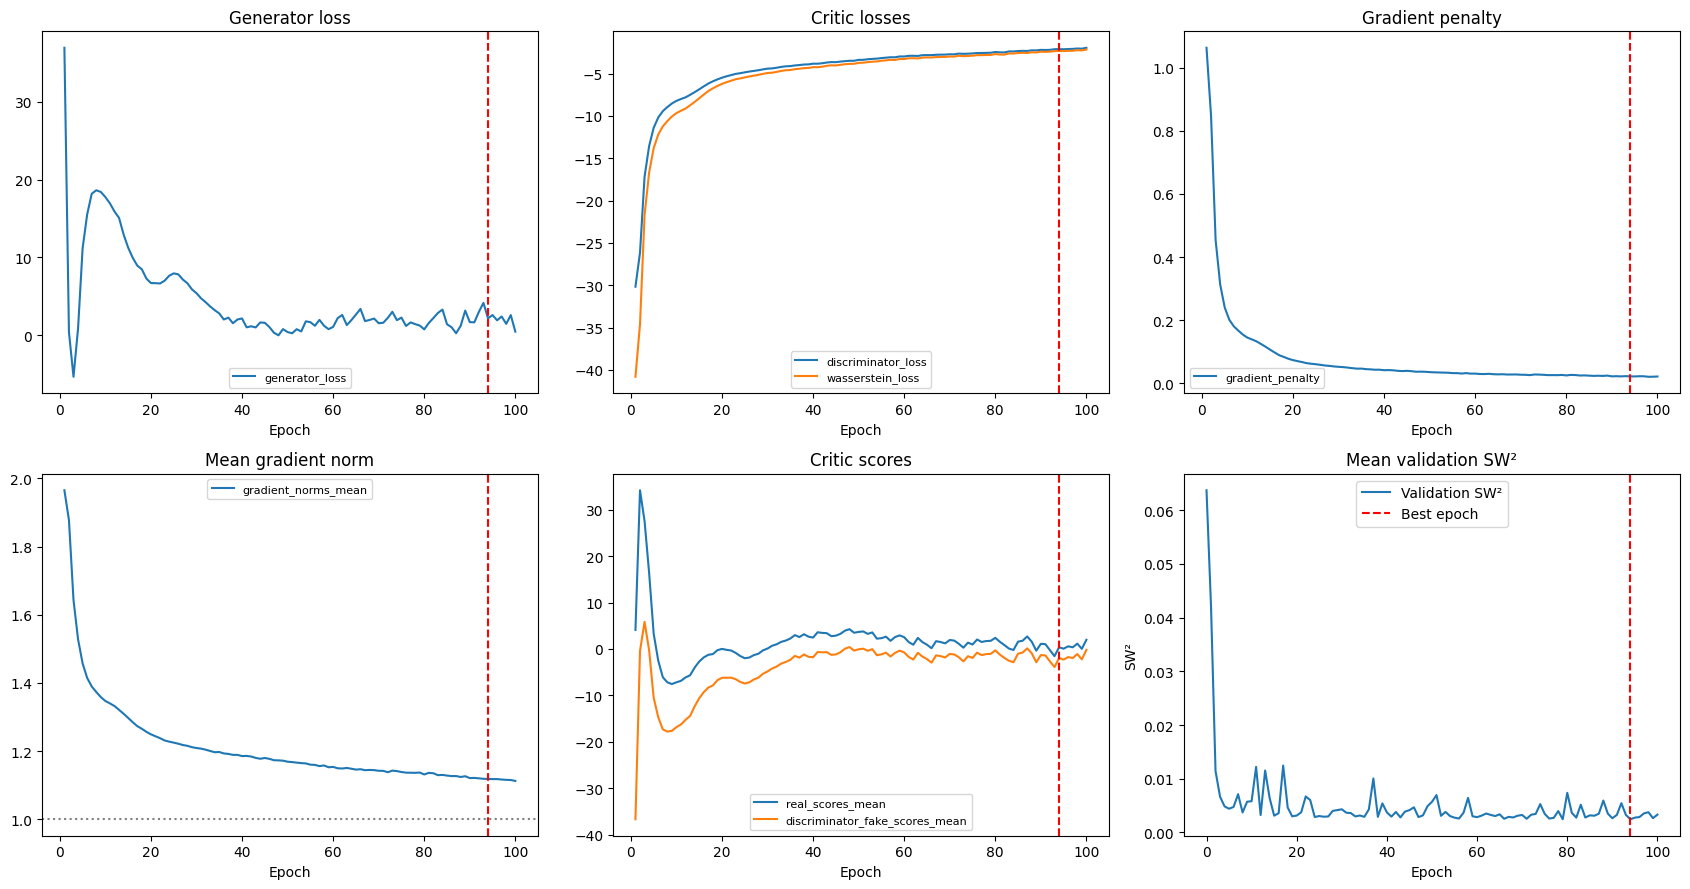

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plots = [
  (["generator_loss"], "Generator loss"),
  (["discriminator_loss", "wasserstein_loss"], "Critic losses"),
  (["gradient_penalty"], "Gradient penalty"),
  (["gradient_norms_mean"], "Mean gradient norm"),
  (["real_scores_mean", "discriminator_fake_scores_mean"], "Critic scores"),
]

for ax, (columns, title) in zip(axes.flat, plots):
  for column in columns:
    ax.plot(training_epochs, training_history[column], label=column)
  ax.axvline(best_epoch, color="red", linestyle="--")
  ax.set(title=title, xlabel="Epoch")
  ax.legend(fontsize=8)

axes[1, 0].axhline(1, color="gray", linestyle=":")
axes[1, 2].plot(sw_history["epoch"], sw_history["mean_sw2_squared"], label="Validation SW²")
axes[1, 2].axvline(best_epoch, color="red", linestyle="--", label="Best epoch")
axes[1, 2].set(title="Mean validation SW²", xlabel="Epoch", ylabel="SW²")
axes[1, 2].legend()

plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "training_curves.png", dpi=150)
plt.show()
plt.close(fig)

#### Validation curves by age group

The detailed plots start at epoch 1 to make changes after initialisation easier to see.


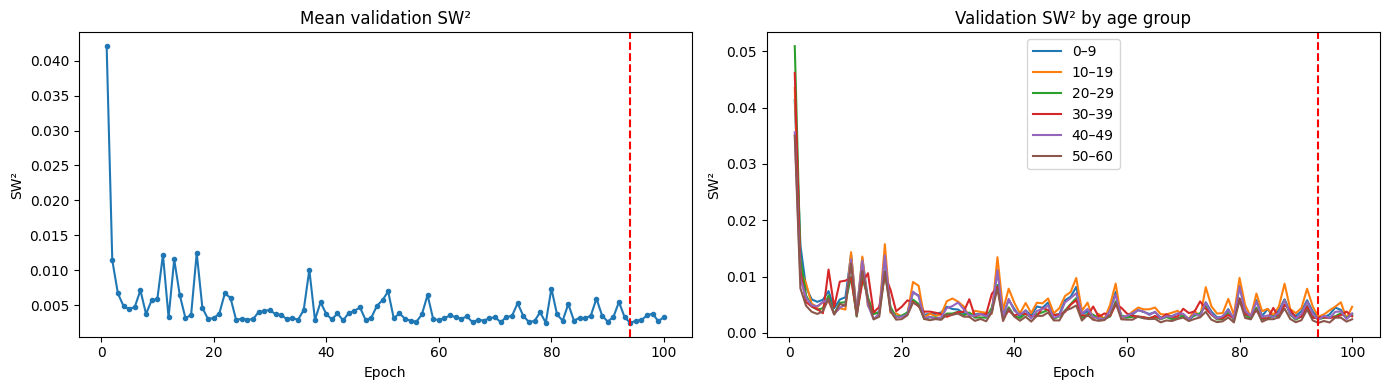

In [70]:
post_initial = sw_history[sw_history["epoch"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(post_initial["epoch"], post_initial["mean_sw2_squared"], marker=".")
axes[0].set(title="Mean validation SW²", xlabel="Epoch", ylabel="SW²")

for group in age_groups:
  axes[1].plot(post_initial["epoch"], post_initial[f"sw2_squared_{group}"], label=group)
axes[1].set(title="Validation SW² by age group", xlabel="Epoch", ylabel="SW²")
axes[1].legend()

for ax in axes:
  ax.axvline(best_epoch, color="red", linestyle="--")

plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "validation_sw_curves.png", dpi=150)
plt.show()
plt.close(fig)

### 5. Generated examples

Each row uses the same noise across age groups to show the effect of changing the condition. Different rows use different noise to show variation within an age group.


In [ ]:
def show_condition_grid(model, noise, conditions, n_rows, title, path):
  generated = model([noise, conditions], training=False).numpy()
  fig, axes = plt.subplots(n_rows, len(age_groups), figsize=(12, n_rows * 2), squeeze=False)
  for col, group in enumerate(age_groups):
    for row in range(n_rows):
      axes[row, col].imshow(generated[col * n_rows + row], interpolation='nearest')
      axes[row, col].axis('off')
      if row == 0:
        axes[row, col].set_title(group)
  fig.suptitle(title)
  fig.tight_layout()
  fig.savefig(path, dpi=150)
  plt.show()
  plt.close(fig)

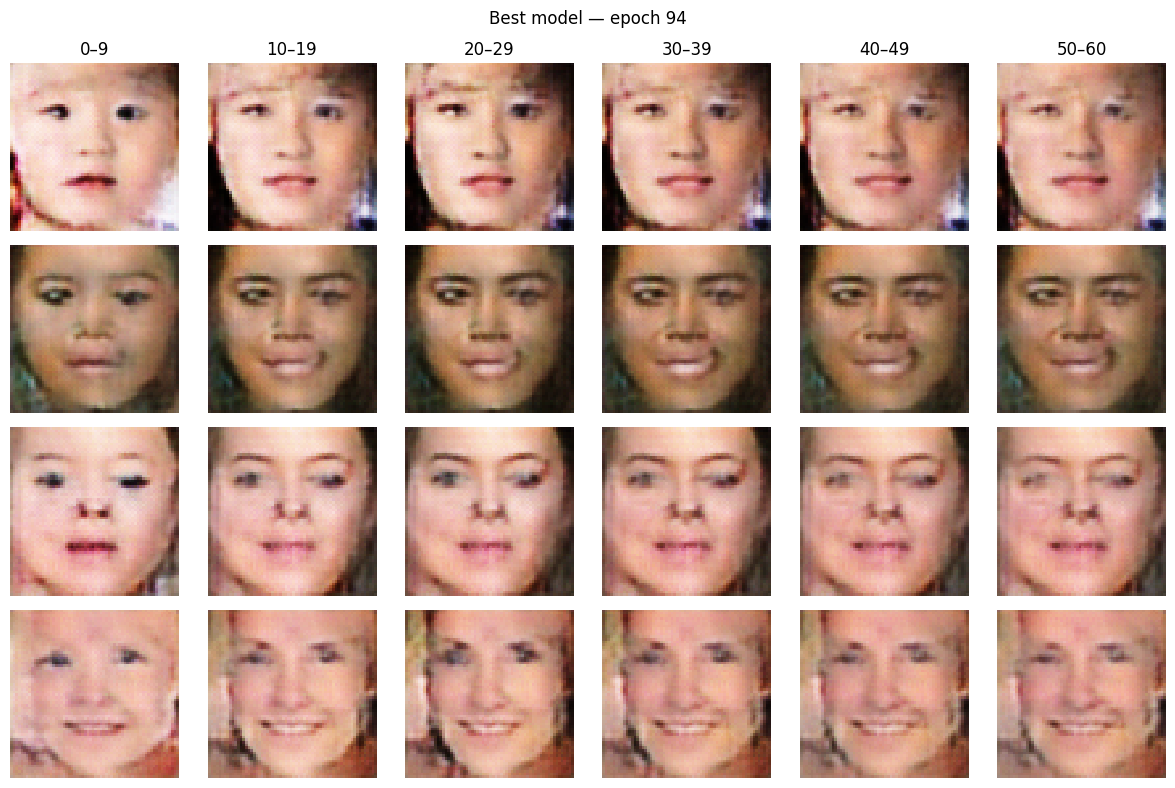

In [72]:
show_condition_grid(
  wgan.generator, fixed_noise, fixed_conditions, N_PER_CLASS,
  f"Best model — epoch {best_epoch}",
  ANALYSIS_DIR / "best_fixed_grid.png"
)

#### Additional examples

Eight new noise vectors show more faces from the selected generator.


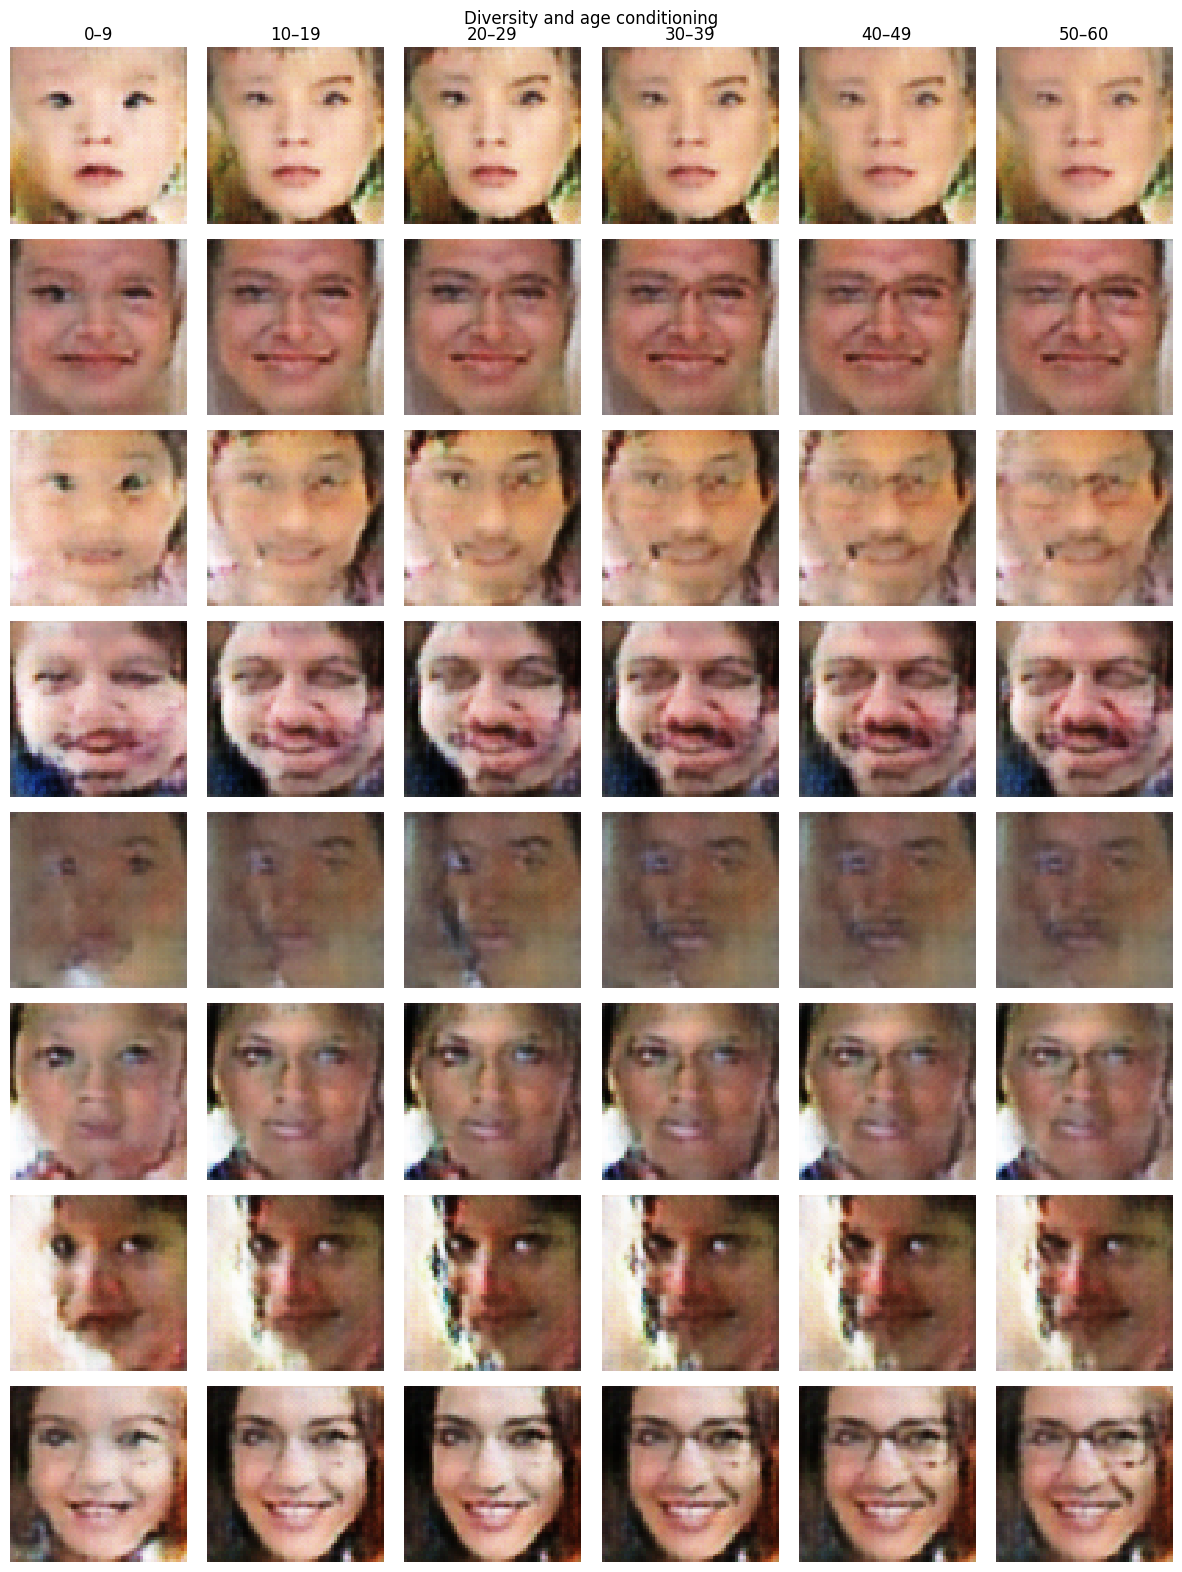

In [73]:
extra_rows = 8
extra_rng = np.random.default_rng(CONFIG["seed"] + 400)
extra_base = extra_rng.standard_normal(
  (extra_rows, CONFIG["latent_dim"])
).astype(np.float32)

extra_noise = np.tile(extra_base, (CONFIG["n_classes"], 1))
extra_ids = np.repeat(np.arange(CONFIG["n_classes"]), extra_rows)
extra_conditions = keras.utils.to_categorical(
  extra_ids, num_classes=CONFIG["n_classes"]
).astype(np.float32)

show_condition_grid(
  wgan.generator, extra_noise, extra_conditions, extra_rows,
  "Diversity and age conditioning", ANALYSIS_DIR / "diversity_grid.png"
)

#### Training animation

The animation uses the saved image grids to show how the generated faces change during training.


In [ ]:
from PIL import Image
from IPython.display import Image as NotebookImage
frame_paths = sorted((RUN_DIR / 'frames').glob('epoch_*.png'))
assert frame_paths, 'No saved frames.'
frames = []
for frame_path in frame_paths:
    with Image.open(frame_path) as frame:
        # Smaller GIF, same saved original PNG frames.
        frame = frame.convert('RGB')
        frame.thumbnail((720, 720))
        frames.append(frame.copy())
gif_path = RUN_DIR / 'training_evolution.gif'
frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=300, loop=0)
display(NotebookImage(filename=str(gif_path)))
del frames

### 6. Validation analysis

The condition matrix compares each real age group with every generated age group.


In [ ]:
def conditions_for(class_id, count):
  labels = np.full(count, class_id)
  return keras.utils.to_categorical(
    labels, num_classes=CONFIG["n_classes"]
  ).astype(np.float32)

In [ ]:
def measured_sw(real_images, generated_images, seed):
  count = len(real_images)
  real_flat = tf.reshape(tf.cast(real_images, tf.float32), (count, -1))
  generated_flat = tf.reshape(tf.cast(generated_images, tf.float32), (count, -1))

  value = sw_loss(
    true_distribution=real_flat,
    generated_distribution=generated_flat,
    num_projections=CONFIG["sw_num_projections"],
    batch_size=count,
    seed=seed
  )
  return float(value.numpy())

In [ ]:
def save_matrix(matrix, title, path):
  fig, ax = plt.subplots(figsize=(8, 6))
  plot = ax.imshow(matrix, cmap="viridis_r")
  ax.set_xticks(range(len(age_groups)), age_groups)
  ax.set_yticks(range(len(age_groups)), age_groups)
  ax.set(title=title, xlabel="Generated condition", ylabel="Real age group")

  for row in range(len(age_groups)):
    for col in range(len(age_groups)):
      ax.text(
        col, row, f"{matrix[row, col]:.4f}", ha="center", va="center",
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"), fontsize=8
      )

  fig.colorbar(plot, ax=ax, label="SW² — lower is better")
  plt.tight_layout()
  fig.savefig(path, dpi=150)
  plt.show()
  plt.close(fig)

#### Condition matrix

Rows are real age groups and columns are requested age groups. Lower values indicate closer distributions. Five sets of projection directions are used with fixed images and noise.


In [ ]:
def calculate_matrices(model, real_images, positions, noise):
  real_sets = []
  generated_sets = []
  count = len(noise)

  for class_id in range(CONFIG["n_classes"]):
    real_sets.append(real_images[positions[class_id]])
    conditions = conditions_for(class_id, count)
    generated = model([noise, conditions], training=False).numpy()
    generated_sets.append(generated)

  matrices = np.zeros((CONFIG["evaluation_repeats"], len(age_groups), len(age_groups)))
  for repeat in range(CONFIG["evaluation_repeats"]):
    seed = (CONFIG["seed"], 500 + repeat)
    for row in range(len(age_groups)):
      for col in range(len(age_groups)):
        matrices[repeat, row, col] = measured_sw(real_sets[row], generated_sets[col], seed)
    print(f"Projection repeat {repeat + 1}/{CONFIG['evaluation_repeats']}")

  return matrices

#### Matching and alternative conditions

The diagonal compares matching age groups. A positive margin means the matching condition has a lower distance than the closest alternative.


In [ ]:
def summarise_matrices(matrices):
  rows = []
  for class_id, group in enumerate(age_groups):
    correct = matrices[:, class_id, class_id]
    wrong = np.delete(matrices[:, class_id, :], class_id, axis=1)
    margin = wrong.min(axis=1) - correct
    rows.append({
      "age_group": group,
      "sw2_squared_mean": correct.mean(),
      "sw2_squared_std": correct.std(ddof=1),
      "diagonal_min_count": int((margin >= 0).sum()),
      "repeats": len(matrices),
      "margin_mean": margin.mean()
    })
  return pd.DataFrame(rows)

In [ ]:
def evaluate_condition_matrix(model, real_images, real_labels, selected_positions, noise, output_dir):
  output_dir = Path(output_dir)
  output_dir.mkdir(parents=True, exist_ok=True)

  matrices = calculate_matrices(model, real_images, selected_positions, noise)
  summary = summarise_matrices(matrices)
  mean_matrix = matrices.mean(axis=0)
  matrix_table = pd.DataFrame(mean_matrix, index=age_groups, columns=age_groups)
  matrix_table.index.name = "Real age group"
  matrix_table.columns.name = "Generated condition"

  display(summary.round(6))
  display(matrix_table.round(6))
  summary.to_csv(output_dir / "sw_by_age.csv", index=False)
  matrix_table.to_csv(output_dir / "sw_matrix_mean.csv")
  np.savez(
    output_dir / "evaluation.npz", matrices=matrices, noise=noise,
    selected_positions=np.stack(selected_positions)
  )
  save_matrix(mean_matrix, "SW² by condition", output_dir / "sw_matrix.png")
  return summary, matrices

#### Validation results

The first table shows the per-age scores used for model selection. The matrix uses projection directions shared across all comparisons, so its diagonal can differ slightly.


In [81]:
best_by_age = pd.DataFrame({
  "age_group": age_groups,
  "sw2_squared": [best_row[f"sw2_squared_{group}"] for group in age_groups]
})
display(best_by_age)

,age_group,sw2_squared
0,0–9,0.002652
1,10–19,0.002874
2,20–29,0.002423
3,30–39,0.002746
4,40–49,0.002301
5,50–60,0.001774


Projection repeat 1/5
Projection repeat 2/5
Projection repeat 3/5
Projection repeat 4/5
Projection repeat 5/5


,age_group,sw2_squared_mean,sw2_squared_std,diagonal_min_count,repeats,margin_mean
0,0–9,0.002427,0.000168,5,5,0.009804
1,10–19,0.002907,0.000238,5,5,0.001924
2,20–29,0.002422,0.000128,5,5,0.000369
3,30–39,0.002722,0.000126,5,5,0.000677
4,40–49,0.002081,0.000060,5,5,0.000280
5,50–60,0.001854,0.000065,5,5,0.000346


Generated condition,0–9,10–19,20–29,30–39,40–49,50–60
Real age group,,,,,,
0–9,0.002427,0.012454,0.017411,0.017060,0.015371,0.012687
10–19,0.007236,0.002907,0.004847,0.005408,0.005785,0.005554
20–29,0.015252,0.003668,0.002422,0.002791,0.004116,0.005269
30–39,0.018028,0.005822,0.004332,0.002722,0.003399,0.004652
40–49,0.011511,0.004522,0.004759,0.002595,0.002081,0.002361
50–60,0.009797,0.004630,0.005156,0.003029,0.002200,0.001854


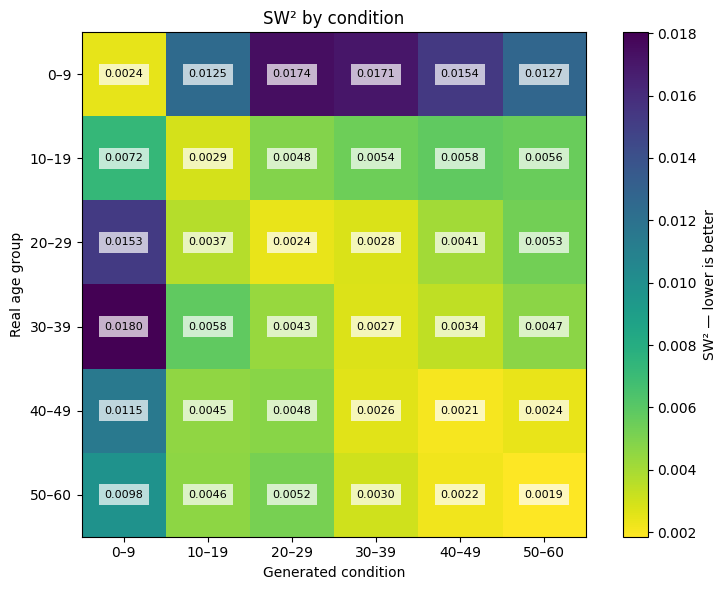

In [82]:
val_summary, val_matrices = evaluate_condition_matrix(
  wgan.generator, x_valid, y_valid,
  [sw_valid_positions[c] for c in range(CONFIG["n_classes"])],
  sw_fixed_noise, ANALYSIS_DIR / "validation_matrix"
)

#### Real, blurred and generated images

For each age group, sets A and B contain 50 different real images each. We compare A with itself, B, two blurred versions of A and generated faces. The blurred versions show how the score responds to reduced sharpness.


In [ ]:
def prepare_references(model, images, labels, seed_offset):
  count = 50
  rng = np.random.default_rng(CONFIG["seed"] + seed_offset)
  noise_rng = np.random.default_rng(CONFIG["seed"] + seed_offset + 1)
  noise = noise_rng.standard_normal((count, CONFIG["latent_dim"])).astype(np.float32)
  image_sets = {}

  for class_id in range(CONFIG["n_classes"]):
    candidates = np.flatnonzero(labels == class_id)
    selected = rng.choice(candidates, size=2 * count, replace=False)
    real_a = images[selected[:count]]
    real_b = images[selected[count:]]
    conditions = conditions_for(class_id, count)

    image_sets[class_id] = {
      "real_a": real_a,
      "real_b": real_b,
      "blur_sigma_1": gaussian_filter(real_a, sigma=(0, 1, 1, 0), mode="reflect"),
      "blur_sigma_2": gaussian_filter(real_a, sigma=(0, 2, 2, 0), mode="reflect"),
      "generated": model([noise, conditions], training=False).numpy()
    }

  return image_sets

In [ ]:
def calculate_references(image_sets):
  rows = []
  for class_id, group in enumerate(age_groups):
    real_a = image_sets[class_id]["real_a"]
    for repeat in range(CONFIG["evaluation_repeats"]):
      seed = (CONFIG["seed"], 300 + repeat)
      for name, other in image_sets[class_id].items():
        rows.append({
          "age_group": group,
          "comparison": name,
          "repeat": repeat,
          "sw2_squared": measured_sw(real_a, other, seed)
        })

  results = pd.DataFrame(rows)
  summary = results.groupby(["age_group", "comparison"], sort=False)["sw2_squared"].agg(
    ["mean", "std"]
  ).reset_index()
  return results, summary

#### Reference image grid

The generated column uses the same noise for every age group so that only the requested condition changes.


In [ ]:
def show_reference_images(image_sets, path):
  keys = ["real_a", "real_b", "blur_sigma_1", "blur_sigma_2", "generated"]
  titles = ["Real A", "Real B", "A: blur σ=1", "A: blur σ=2", "Generated"]
  fig, axes = plt.subplots(len(age_groups), len(keys), figsize=(10, 12), squeeze=False)

  for row, group in enumerate(age_groups):
    for col, key in enumerate(keys):
      axes[row, col].imshow(image_sets[row][key][0], interpolation="nearest")
      axes[row, col].set_xticks([])
      axes[row, col].set_yticks([])
      if row == 0:
        axes[row, col].set_title(titles[col])
      if col == 0:
        axes[row, col].set_ylabel(group)

  plt.tight_layout()
  fig.savefig(path, dpi=150)
  plt.show()
  plt.close(fig)

#### Reference distances

Error bars show variation across projection seeds. The blurred images come from the same real images in set A, so this comparison shows how the metric responds to changes in sharpness. The comparison with set B uses different real images.

In [ ]:
def plot_references(summary, path):
  keys = ["real_a", "real_b", "blur_sigma_1", "blur_sigma_2", "generated"]
  captions = ["A–A", "A–B", "Blur 1", "Blur 2", "Generated"]
  fig, axes = plt.subplots(2, 3, figsize=(15, 8))

  for ax, group in zip(axes.flat, age_groups):
    values = summary[summary["age_group"] == group].set_index("comparison").loc[keys]
    ax.bar(range(len(keys)), values["mean"], yerr=values["std"], capsize=3)
    ax.set_xticks(range(len(keys)), captions)
    ax.set(title=group, ylabel="SW²")

  plt.tight_layout()
  fig.savefig(path, dpi=150)
  plt.show()
  plt.close(fig)

In [87]:
validation_sets = prepare_references(wgan.generator, x_valid, y_valid, seed_offset=200)
validation_results, validation_references = calculate_references(validation_sets)

validation_results.to_csv(ANALYSIS_DIR / "validation_reference_repeats.csv", index=False)
validation_references.to_csv(ANALYSIS_DIR / "validation_references.csv", index=False)
display(validation_references.pivot(
  index="age_group", columns="comparison", values="mean"
).reindex(age_groups).round(6))

comparison,blur_sigma_1,blur_sigma_2,generated,real_a,real_b
age_group,,,,,
0–9,0.000444,0.001372,0.005318,0.0,0.004389
10–19,0.000519,0.001571,0.005073,0.0,0.004484
20–29,0.000524,0.001720,0.005603,0.0,0.005330
30–39,0.000504,0.001581,0.004800,0.0,0.004381
40–49,0.000440,0.001352,0.006299,0.0,0.005089
50–60,0.000443,0.001278,0.004356,0.0,0.003652


In [ ]:
show_reference_images(validation_sets, ANALYSIS_DIR / "validation_reference_images.png")

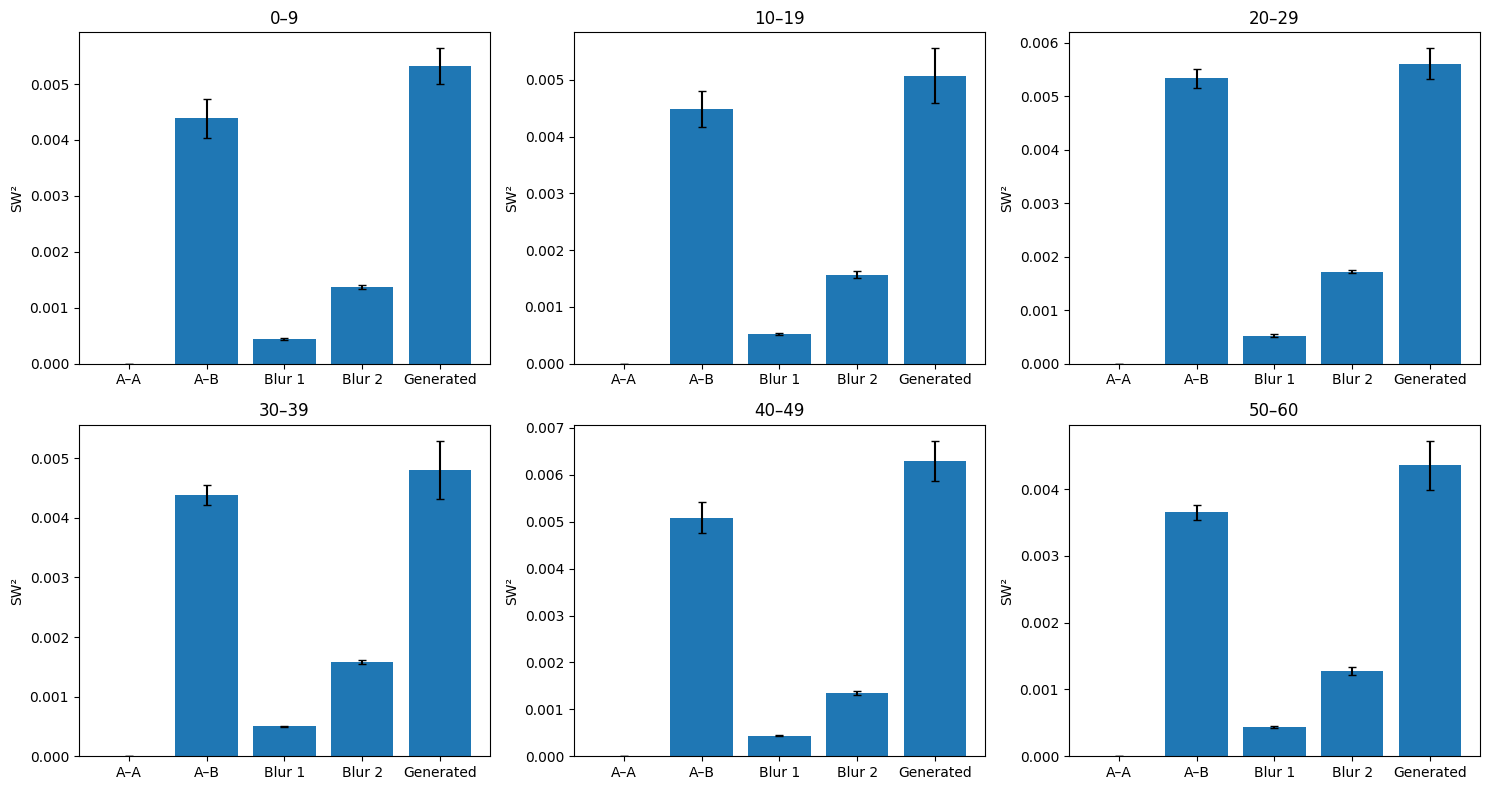

In [89]:
plot_references(validation_references, ANALYSIS_DIR / "validation_reference_sw.png")

### 7. Test evaluation

We evaluate the selected model on held-out images using up to 100 real images per age group. We draw fresh noise and reuse the projection seeds from the validation matrix.


In [90]:
test_counts = np.bincount(y_test, minlength=CONFIG["n_classes"])
TEST_N = min(SW_SAMPLES_PER_CLASS, int(test_counts.min()))
test_rng = np.random.default_rng(CONFIG["seed"] + 600)
test_positions = []

for class_id in range(CONFIG["n_classes"]):
  candidates = np.flatnonzero(y_test == class_id)
  positions = test_rng.choice(candidates, size=TEST_N, replace=False)
  test_positions.append(positions)

test_noise_rng = np.random.default_rng(CONFIG["seed"] + 601)
test_noise = test_noise_rng.standard_normal(
  (TEST_N, CONFIG["latent_dim"])
).astype(np.float32)

display(pd.DataFrame({
  "age_group": age_groups,
  "available_images": test_counts,
  "evaluated_images": TEST_N
}))

,age_group,available_images,evaluated_images
0,0–9,246,100
1,10–19,122,100
2,20–29,471,100
3,30–39,284,100
4,40–49,143,100
5,50–60,183,100


#### Test condition matrix


Projection repeat 1/5
Projection repeat 2/5
Projection repeat 3/5
Projection repeat 4/5
Projection repeat 5/5


,age_group,sw2_squared_mean,sw2_squared_std,diagonal_min_count,repeats,margin_mean
0,0–9,0.002222,0.000082,5,5,0.005911
1,10–19,0.002921,0.000139,5,5,0.000387
2,20–29,0.004425,0.000435,3,5,0.000198
3,30–39,0.003986,0.000372,5,5,0.000853
4,40–49,0.003168,0.000122,0,5,-0.000416
5,50–60,0.002643,0.000169,0,5,-0.000197


Generated condition,0–9,10–19,20–29,30–39,40–49,50–60
Real age group,,,,,,
0–9,0.002222,0.008439,0.012370,0.011869,0.010440,0.008647
10–19,0.013484,0.002921,0.003308,0.003690,0.004501,0.005454
20–29,0.024010,0.007375,0.004425,0.004623,0.006600,0.008951
30–39,0.022903,0.007547,0.005740,0.003986,0.004840,0.006534
40–49,0.019264,0.006274,0.004689,0.002752,0.003168,0.004754
50–60,0.012757,0.004606,0.004711,0.002706,0.002446,0.002643


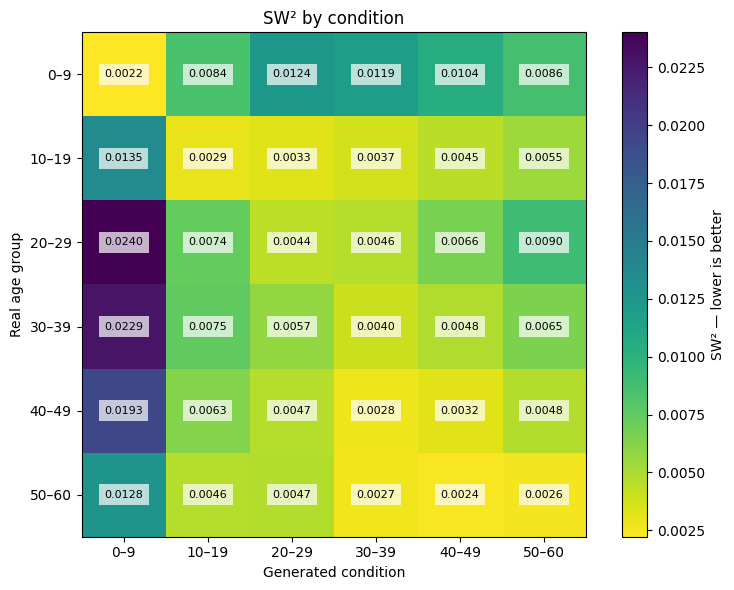

In [91]:
test_summary, test_matrices = evaluate_condition_matrix(
  wgan.generator, x_test, y_test, test_positions,
  test_noise, ANALYSIS_DIR / "test_matrix"
)

#### Test reference comparison

The real and blurred references are recomputed with test images.


In [92]:
test_sets = prepare_references(wgan.generator, x_test, y_test, seed_offset=700)
test_results, test_references = calculate_references(test_sets)

test_results.to_csv(ANALYSIS_DIR / "test_reference_repeats.csv", index=False)
test_references.to_csv(ANALYSIS_DIR / "test_references.csv", index=False)
display(test_references.pivot(
  index="age_group", columns="comparison", values="mean"
).reindex(age_groups).round(6))

comparison,blur_sigma_1,blur_sigma_2,generated,real_a,real_b
age_group,,,,,
0–9,0.000504,0.001561,0.005739,0.0,0.004752
10–19,0.000557,0.001664,0.004458,0.0,0.004959
20–29,0.000508,0.001607,0.008312,0.0,0.004531
30–39,0.000517,0.001613,0.005502,0.0,0.004774
40–49,0.000424,0.001329,0.005698,0.0,0.005785
50–60,0.000465,0.001413,0.005339,0.0,0.005493


In [ ]:
show_reference_images(test_sets, ANALYSIS_DIR / "test_reference_images.png")

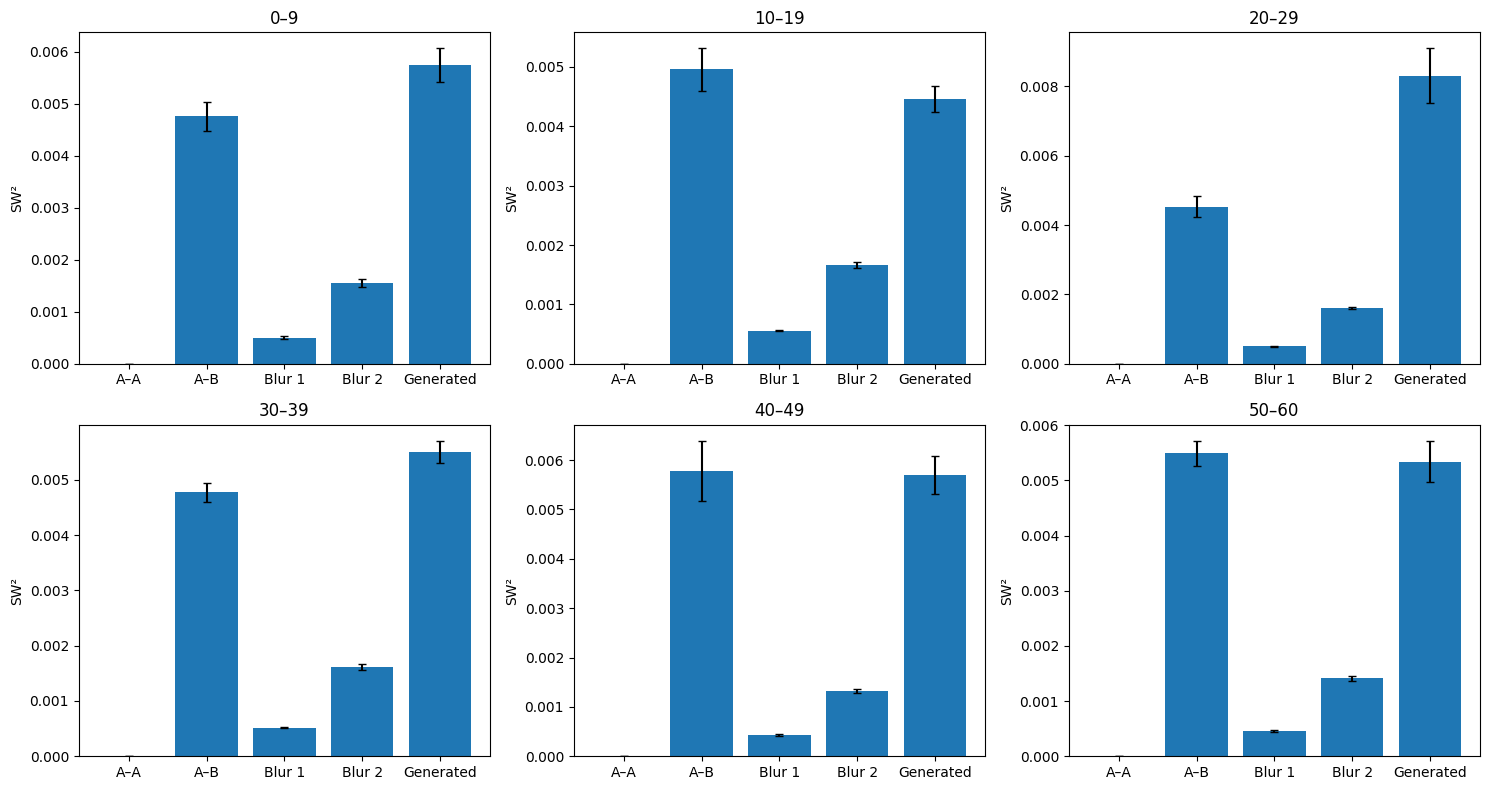

In [94]:
plot_references(test_references, ANALYSIS_DIR / "test_reference_sw.png")

### 8. Validation and test comparison

The plot compares matching-condition scores by age group. It uses different real samples and noise for the two splits.


In [95]:
comparison = pd.DataFrame({
  "age_group": age_groups,
  "validation_sw": val_summary["sw2_squared_mean"].to_numpy(),
  "test_sw": test_summary["sw2_squared_mean"].to_numpy()
})
comparison["test_minus_validation"] = comparison["test_sw"] - comparison["validation_sw"]
display(comparison.round(6))
comparison.to_csv(ANALYSIS_DIR / "validation_test_comparison.csv", index=False)

,age_group,validation_sw,test_sw,test_minus_validation
0,0–9,0.002427,0.002222,-0.000204
1,10–19,0.002907,0.002921,0.000014
2,20–29,0.002422,0.004425,0.002003
3,30–39,0.002722,0.003986,0.001264
4,40–49,0.002081,0.003168,0.001087
5,50–60,0.001854,0.002643,0.000788


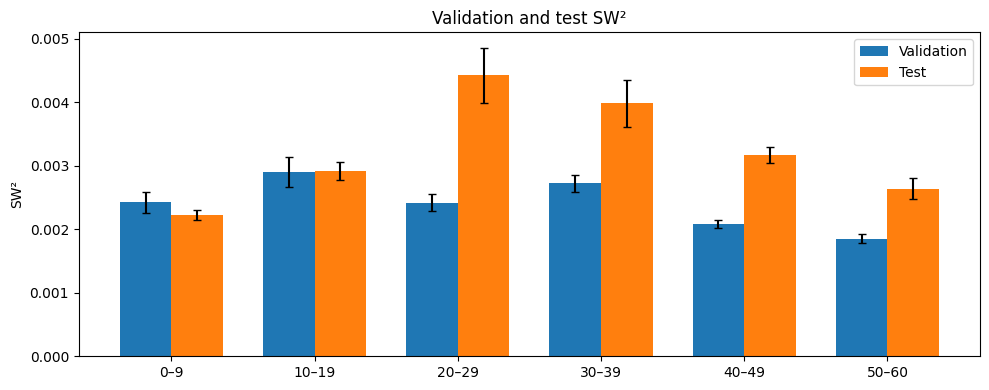

In [96]:
positions = np.arange(len(age_groups))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
  positions - width / 2, comparison["validation_sw"], width,
  yerr=val_summary["sw2_squared_std"], capsize=3, label="Validation"
)
ax.bar(
  positions + width / 2, comparison["test_sw"], width,
  yerr=test_summary["sw2_squared_std"], capsize=3, label="Test"
)
ax.set_xticks(positions, age_groups)
ax.set(title="Validation and test SW²", ylabel="SW²")
ax.legend()
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "validation_test_sw.png", dpi=150)
plt.show()
plt.close(fig)

#### Overall scores

Each age group has equal weight. The reported standard deviation measures variation across projection seeds.


In [97]:
val_macro = np.diagonal(val_matrices, axis1=1, axis2=2).mean(axis=1)
test_macro = np.diagonal(test_matrices, axis1=1, axis2=2).mean(axis=1)

final_results = pd.DataFrame({
  "split": ["Validation", "Test"],
  "images_per_age_group": [SW_SAMPLES_PER_CLASS, TEST_N],
  "mean_sw2_squared": [val_macro.mean(), test_macro.mean()],
  "projection_std": [val_macro.std(ddof=1), test_macro.std(ddof=1)]
})
display(final_results.round(6))
final_results.to_csv(ANALYSIS_DIR / "final_results.csv", index=False)

print("Epochs trained:", len(history.epoch))
print("Best epoch:", best_epoch)
print("Best validation SW²:", float(best_row["mean_sw2_squared"]))
print("Results saved to:", ANALYSIS_DIR)

,split,images_per_age_group,mean_sw2_squared,projection_std
0,Validation,100,0.002402,0.000072
1,Test,100,0.003228,0.000124


Epochs trained: 100
Best epoch: 94
Best validation SW²: 0.002461520217669507


## Conclusion

The conditional WGAN-GP generated faces for six age groups. The model selected at epoch 94 achieved a mean squared Sliced Wasserstein distance of 0.00240 on the validation set and 0.00323 on the test set.

On validation, the matching age condition gave the lowest distance for all six groups. On test, this pattern was less consistent, especially for the 40–49 and 50–60 groups.

The generated images varied with the input noise, and changing the age condition affected some facial features. The differences were often subtle between adult groups, and some images showed blur or distortions. The scores and image grids together suggest that the model learned some age-related differences, with clearer results for some groups than for others.

## References

- [Keras WGAN-GP](https://keras.io/examples/generative/wgan_gp/) for the training loop and gradient penalty.
- [Keras Conditional GAN](https://keras.io/examples/generative/conditional_gan/) for class conditioning.
- [TensorFlow DCGAN tutorial](https://www.tensorflow.org/tutorials/generative/dcgan?hl=pt-br) for the training animation.
- [Émilien Dupont’s WGAN-GP implementation](https://github.com/EmilienDupont/wgan-gp/tree/master) for comparison.
- The Sliced Wasserstein evaluation function was provided with the lab and is attributed in the notebook.